# Outcome 3 — Klasifikasi Beban Motor Menggunakan Support Vector Machine (SVM).

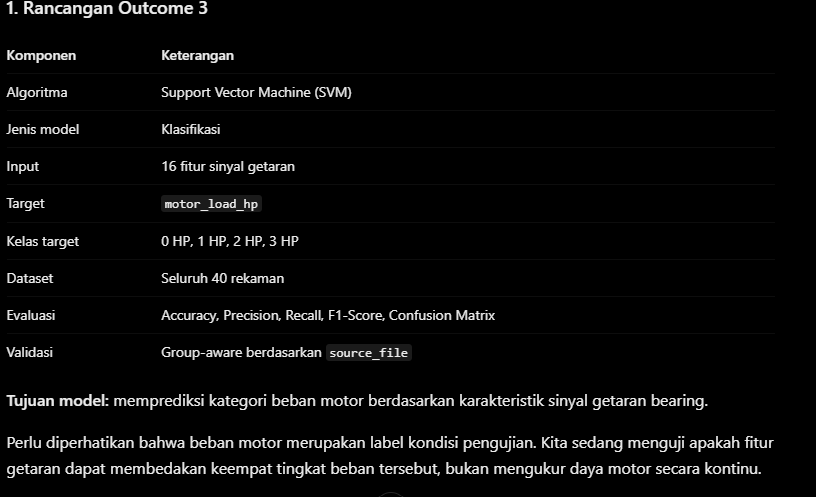

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Seluruh library berhasil diimport.")


Seluruh library berhasil diimport.


In [2]:
# Membaca dataset
DATA_PATH = Path("outputs/bearing_features.csv")

df = pd.read_csv(DATA_PATH)

print("Jumlah segmen:", len(df))
print("Jumlah rekaman:", df["source_file"].nunique())

print("\nDistribusi beban motor:")
print(df["motor_load_hp"].value_counts().sort_index())

print("\nJumlah rekaman setiap beban:")
print(
    df.groupby("motor_load_hp")["source_file"]
    .nunique()
)

display(df.head())


Jumlah segmen: 3993
Jumlah rekaman: 40

Distribusi beban motor:
motor_load_hp
0     961
1    1010
2    1010
3    1012
Name: count, dtype: int64

Jumlah rekaman setiap beban:
motor_load_hp
0    10
1    10
2    10
3    10
Name: source_file, dtype: int64


,source_file,segment_id,start_sample,end_sample,condition,defect_size_inch,motor_load_hp,mean,std,rms,...,peak_amplitude,crest_factor,dominant_frequency,spectral_centroid,spectral_bandwidth,spectral_entropy,total_spectral_power,band_power_low,band_power_mid,band_power_high
0,97.mat,0,0,1199,Normal,NaN,0,-0.000437,0.072389,0.072390,...,0.216706,2.993599,4148.4375,3076.863339,1588.327631,5.084973,0.004946,0.001197,0.000463,0.003284
1,97.mat,1,1200,2399,Normal,NaN,0,0.000018,0.069990,0.069990,...,0.242119,3.459334,4148.4375,3169.305563,1537.997776,5.200270,0.004990,0.001109,0.000463,0.003413
2,97.mat,2,2400,3599,Normal,NaN,0,-0.000180,0.068403,0.068404,...,0.247259,3.614699,4148.4375,3291.095042,1460.725365,5.149379,0.004693,0.000829,0.000444,0.003418
3,97.mat,3,3600,4799,Normal,NaN,0,0.000025,0.070061,0.070061,...,0.244666,3.492195,4148.4375,3225.832963,1485.812198,5.089351,0.004650,0.000933,0.000481,0.003236
4,97.mat,4,4800,5999,Normal,NaN,0,-0.000124,0.069863,0.069863,...,0.210170,3.008313,4148.4375,3150.739684,1549.269331,5.254523,0.004976,0.001069,0.000460,0.003446


In [3]:
# Menentukan fitur dan target
feature_columns = [
    "mean", "std", "rms", "skewness",
    "kurtosis", "peak_to_peak",
    "peak_amplitude", "crest_factor",
    "dominant_frequency", "spectral_centroid",
    "spectral_bandwidth", "spectral_entropy",
    "total_spectral_power",
    "band_power_low", "band_power_mid",
    "band_power_high"
]

X = df[feature_columns]
y = df["motor_load_hp"].astype(int)
groups = df["source_file"]

assert np.isfinite(X.to_numpy()).all()

print("Jumlah fitur:", X.shape[1])
print("Jumlah kelas:", y.nunique())
print("Kelas:", sorted(y.unique()))


Jumlah fitur: 16
Jumlah kelas: 4
Kelas: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [4]:
# CELL 4 - PEMBAGIAN DATA TRAINING DAN TESTING

import numpy as np
import pandas as pd

# Metadata unik setiap rekaman
recording_info = (
    df[[
        "source_file",
        "condition",
        "defect_size_inch",
        "motor_load_hp"
    ]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Kelompok konfigurasi bearing
# Normal menjadi satu kelompok tersendiri
recording_info["bearing_group"] = (
    recording_info["condition"].astype(str)
    + "_"
    + recording_info["defect_size_inch"].astype(str)
)

# Memilih 10 rekaman testing:
# satu dari masing-masing konfigurasi bearing
# Distribusi beban testing: 3, 3, 2, 2
rng = np.random.default_rng(42)

test_rows = []
remaining = {0: 3, 1: 3, 2: 2, 3: 2}

group_names = rng.permutation(
    recording_info["bearing_group"].unique()
)

for group_name in group_names:
    candidates = recording_info[
        recording_info["bearing_group"] == group_name
    ]

    available_loads = [
        load for load, count in remaining.items()
        if count > 0
    ]

    eligible = candidates[
        candidates["motor_load_hp"].isin(available_loads)
    ]

    chosen = eligible.sample(
        n=1,
        random_state=int(rng.integers(0, 1000000))
    )

    test_rows.append(chosen)

    selected_load = int(
        chosen["motor_load_hp"].iloc[0]
    )

    remaining[selected_load] -= 1

test_recordings = pd.concat(
    test_rows, ignore_index=True
)

test_files = test_recordings["source_file"].tolist()

train_files = recording_info.loc[
    ~recording_info["source_file"].isin(test_files),
    "source_file"
].tolist()

# Membagi fitur dan target berdasarkan rekaman
train_mask = groups.isin(train_files)
test_mask = groups.isin(test_files)

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

# Validasi
assert set(train_files).isdisjoint(set(test_files))
assert all(count == 0 for count in remaining.values())
assert len(train_files) == 30
assert len(test_files) == 10

print("HASIL PEMBAGIAN DATA")
print("=" * 40)
print("Rekaman Training :", len(train_files))
print("Rekaman Testing  :", len(test_files))
print("Segmen Training  :", len(X_train))
print("Segmen Testing   :", len(X_test))

print("\nDistribusi Beban Motor (Rekaman):")
print(
    pd.crosstab(
        recording_info["motor_load_hp"],
        np.where(
            recording_info["source_file"].isin(test_files),
            "Testing",
            "Training"
        )
    )
)

print("\nDaftar Rekaman Testing:")
display(
    test_recordings.sort_values(
        ["condition", "defect_size_inch"]
    )
)


HASIL PEMBAGIAN DATA
Rekaman Training : 30
Rekaman Testing  : 10
Segmen Training  : 2981
Segmen Testing   : 1012

Distribusi Beban Motor (Rekaman):
col_0          Testing  Training
motor_load_hp                   
0                    3         7
1                    3         7
2                    2         8
3                    2         8

Daftar Rekaman Testing:


,source_file,condition,defect_size_inch,motor_load_hp,bearing_group
5,119.mat,Ball Fault,0.007,1,Ball Fault_0.007
0,185.mat,Ball Fault,0.014,0,Ball Fault_0.014
9,223.mat,Ball Fault,0.021,1,Ball Fault_0.021
8,108.mat,Inner Race,0.007,3,Inner Race_0.007
6,170.mat,Inner Race,0.014,1,Inner Race_0.014
3,211.mat,Inner Race,0.021,2,Inner Race_0.021
2,99.mat,Normal,NaN,2,Normal_nan
4,130.mat,Outer Race,0.007,0,Outer Race_0.007
1,200.mat,Outer Race,0.014,3,Outer Race_0.014
7,234.mat,Outer Race,0.021,0,Outer Race_0.021


In [5]:
# melatih model Random Forest
from sklearn.ensemble import RandomForestClassifier

model_rf_load = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=3,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_rf_load.fit(X_train, y_train)

print("Random Forest berhasil dilatih!")


Random Forest berhasil dilatih!


In [6]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_pred = model_rf_load.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("HASIL EVALUASI RANDOM FOREST")
print("=" * 40)
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2, 3],
        zero_division=0
    )
)


HASIL EVALUASI RANDOM FOREST
Accuracy  : 0.0059
Precision : 0.0087
Recall    : 0.0049
F1-Score  : 0.0062

Classification Report:
              precision    recall  f1-score   support

           0       0.03      0.02      0.02       304
           1       0.00      0.00      0.00       303
           2       0.00      0.00      0.00       202
           3       0.00      0.00      0.00       203

    accuracy                           0.01      1012
   macro avg       0.01      0.00      0.01      1012
weighted avg       0.01      0.01      0.01      1012



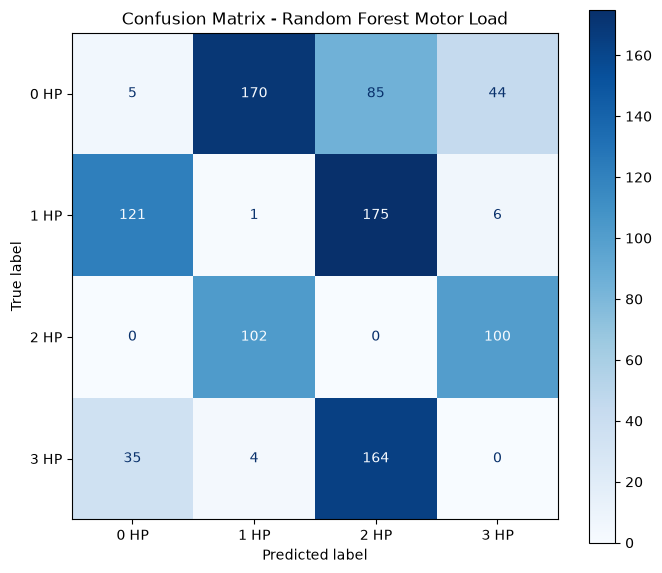

In [7]:

from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3],
    display_labels=["0 HP", "1 HP", "2 HP", "3 HP"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Confusion Matrix - Random Forest Motor Load")
plt.tight_layout()
plt.show()


In [8]:

train_pred = model_rf_load.predict(X_train)
test_pred = model_rf_load.predict(X_test)

performance_df = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [
        accuracy_score(y_train, train_pred),
        accuracy_score(y_test, test_pred)
    ],
    "Macro F1": [
        f1_score(
            y_train, train_pred,
            average="macro", zero_division=0
        ),
        f1_score(
            y_test, test_pred,
            average="macro", zero_division=0
        )
    ]
})

display(performance_df.round(4))


,Dataset,Accuracy,Macro F1
0,Training,0.9799,0.9800
1,Testing,0.0059,0.0062


,Feature,Importance
8,dominant_frequency,0.213797
9,spectral_centroid,0.087686
14,band_power_mid,0.085496
10,spectral_bandwidth,0.081892
13,band_power_low,0.074666
11,spectral_entropy,0.071344
2,rms,0.065330
1,std,0.063004
15,band_power_high,0.058743
4,kurtosis,0.044591


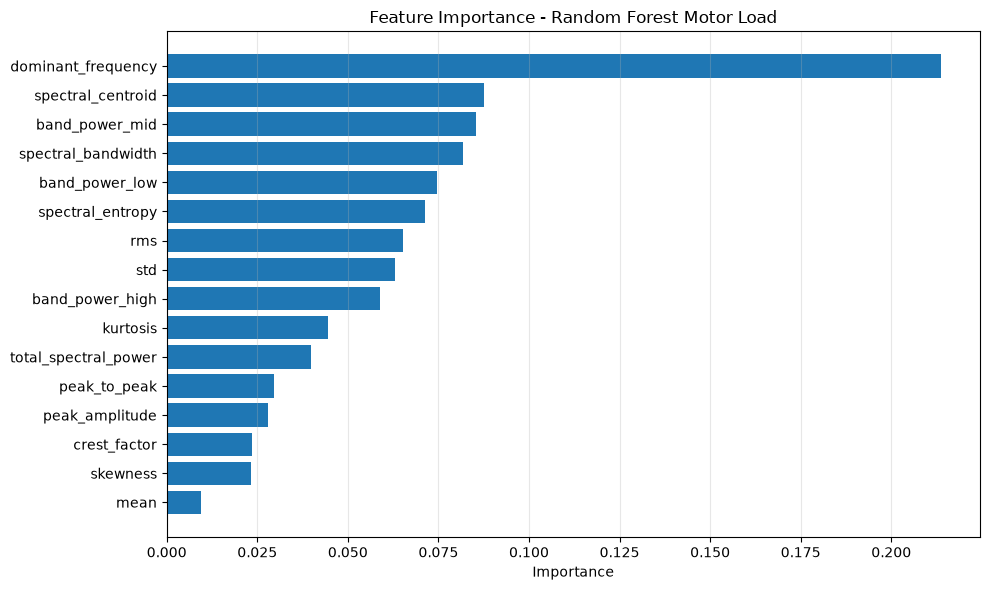

In [9]:

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": model_rf_load.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)

plt.title("Feature Importance - Random Forest Motor Load")
plt.xlabel("Importance")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:

recording_predictions = pd.DataFrame({
    "source_file": groups.loc[test_mask].to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": y_pred
})

recording_results = (
    recording_predictions
    .groupby("source_file")
    .agg(
        actual=("actual", "first"),
        predicted=("predicted", lambda x: x.mode().iloc[0]),
        total_segments=("predicted", "count")
    )
    .reset_index()
)

recording_results["correct"] = (
    recording_results["actual"]
    == recording_results["predicted"]
)

display(recording_results)

print(
    "Recording-level Accuracy:",
    round(recording_results["correct"].mean(), 4)
)


,source_file,actual,predicted,total_segments,correct
0,108.mat,3,2,102,False
1,119.mat,1,0,101,False
2,130.mat,0,1,101,False
3,170.mat,1,2,101,False
4,185.mat,0,2,101,False
5,200.mat,3,2,101,False
6,211.mat,2,3,101,False
7,223.mat,1,2,101,False
8,234.mat,0,1,102,False
9,99.mat,2,1,101,False


Recording-level Accuracy: 0.0


In [11]:

import joblib
from pathlib import Path

MODEL_DIR = Path("outputs/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "model": model_rf_load,
        "feature_columns": feature_columns,
        "target": "motor_load_hp",
        "classes": [0, 1, 2, 3]
    },
    MODEL_DIR / "random_forest_motor_load.joblib"
)

performance_df.to_csv(
    "outputs/rf_motor_load_performance.csv",
    index=False
)

importance_df.to_csv(
    "outputs/rf_motor_load_feature_importance.csv",
    index=False
)

recording_results.to_csv(
    "outputs/rf_motor_load_recording_results.csv",
    index=False
)

print("Model dan hasil evaluasi berhasil disimpan.")


Model dan hasil evaluasi berhasil disimpan.


rms             std         spectral_centroid            \
                 mean     std    mean     std              mean       std   
motor_load_hp                                                               
0              0.2832  0.2225  0.2832  0.2225         2950.2919  195.7140   
1              0.2591  0.1988  0.2591  0.1988         2890.4455  288.8398   
2              0.2622  0.2028  0.2622  0.2028         2849.0596  312.0726   
3              0.2617  0.1970  0.2617  0.1970         2751.7253  335.3406   

              dominant_frequency           kurtosis          
                            mean       std     mean     std  
motor_load_hp                                                
0                      3351.3298  363.1397   5.1526  6.8742  
1                      3015.7117  674.5741   5.0577  6.7324  
2                      2922.4010  895.3170   5.1533  6.9789  
3                      2652.3356  865.1696   4.8784  6.2727

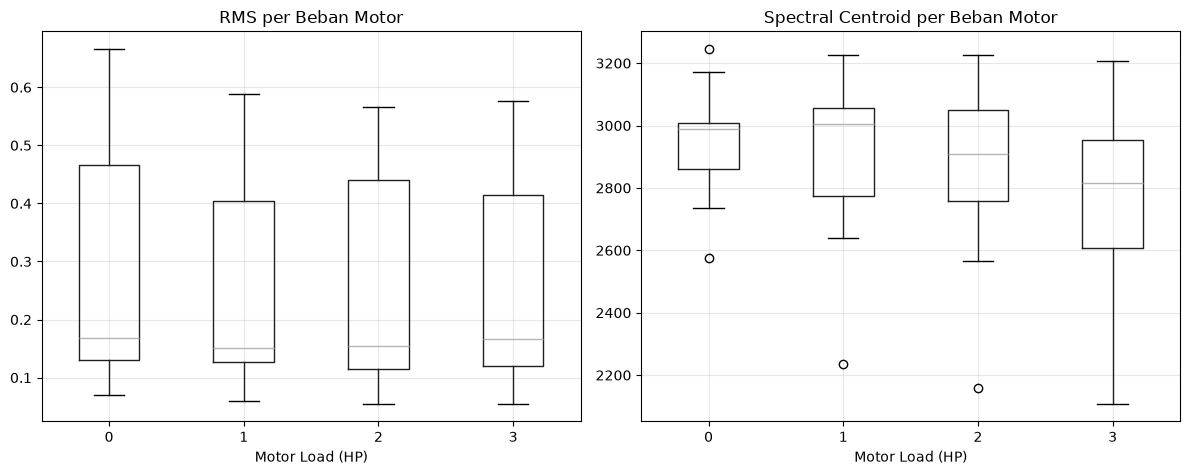

In [12]:

import pandas as pd
import matplotlib.pyplot as plt

# Rata-rata fitur pada setiap rekaman
recording_features = (
    df.groupby(
        ["source_file", "motor_load_hp"],
        as_index=False
    )[feature_columns]
    .mean()
)

# Tampilkan statistik fitur berdasarkan beban motor
feature_summary = (
    recording_features
    .groupby("motor_load_hp")[
        ["rms", "std", "spectral_centroid",
         "dominant_frequency", "kurtosis"]
    ]
    .agg(["mean", "std"])
)

display(feature_summary.round(4))

# Visualisasi distribusi fitur per rekaman
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

recording_features.boxplot(
    column="rms",
    by="motor_load_hp",
    ax=axes[0]
)

recording_features.boxplot(
    column="spectral_centroid",
    by="motor_load_hp",
    ax=axes[1]
)

axes[0].set_title("RMS per Beban Motor")
axes[1].set_title("Spectral Centroid per Beban Motor")

for ax in axes:
    ax.set_xlabel("Motor Load (HP)")
    ax.grid(alpha=0.3)

plt.suptitle("")
plt.tight_layout()
plt.show()


In [19]:

# CELL 13 - VALIDASI LABEL MOTOR LOAD (PERBAIKAN)

expected_groups = {
    0: [97, 105, 169, 209, 118, 185, 222, 130, 197, 234],
    1: [98, 106, 170, 210, 119, 186, 223, 131, 198, 235],
    2: [99, 107, 171, 211, 120, 187, 224, 132, 199, 236],
    3: [100, 108, 172, 212, 121, 188, 225, 133, 200, 237]
}

expected_mapping = {
    f"{file_id}.mat": load
    for load, file_ids in expected_groups.items()
    for file_id in file_ids
}

validation_df = (
    df[["source_file", "motor_load_hp"]]
    .drop_duplicates()
    .copy()
)

validation_df["expected_load"] = (
    validation_df["source_file"].map(expected_mapping)
)

validation_df["valid"] = (
    validation_df["motor_load_hp"]
    == validation_df["expected_load"]
)

display(validation_df.sort_values("source_file"))

print("Jumlah rekaman:", len(validation_df))
print("Label benar:", validation_df["valid"].sum())
print("Label salah:", (~validation_df["valid"]).sum())

assert validation_df["valid"].all(), (
    "Terdapat label beban motor yang tidak sesuai!"
)

print("\nVALIDASI LABEL BERHASIL!")


# MEMBERSIHKAN NAMA FILE DALAM DATAFRAME

df["source_file"] = (
    df["source_file"]
    .astype(str)
    .str.strip()
    .str.replace(r"\s+\.mat$", ".mat", regex=True)
)

# Periksa hasil
print("Nama file setelah dibersihkan:")

print(
    df.loc[
        df["source_file"].str.contains(r"^98\.mat$"),
        "source_file"
    ].unique()
)


,source_file,motor_load_hp,expected_load,valid
251,100.mat,3,3,True
352,105.mat,0,0,True
453,106.mat,1,1,True
554,107.mat,2,2,True
655,108.mat,3,3,True
757,118.mat,0,0,True
859,119.mat,1,1,True
960,120.mat,2,2,True
1061,121.mat,3,3,True
1162,130.mat,0,0,True


Jumlah rekaman: 40
Label benar: 40
Label salah: 0

VALIDASI LABEL BERHASIL!
Nama file setelah dibersihkan:
['98.mat']


In [20]:
# kstraksi fitur frekuensi rendah
import numpy as np
import pandas as pd
from scipy.signal import welch
from pathlib import Path

# Membaca sinyal hasil preprocessing sebelum filtering
signal_df = pd.read_csv(
    "outputs/bearing_clean.csv",
    usecols=[
        "source_file",
        "sample_index",
        "vibration",
        "motor_load_hp"
    ]
)

# Membersihkan nama file
signal_df["source_file"] = (
    signal_df["source_file"]
    .astype(str)
    .str.strip()
    .str.replace(r"\s+\.mat$", ".mat", regex=True)
)

FS = 12000
WINDOW_SIZE = 12000

new_features = []

for file_name, group in signal_df.groupby("source_file"):
    group = group.sort_values("sample_index")

    signal = group["vibration"].to_numpy()
    load = int(group["motor_load_hp"].iloc[0])

    n_segments = len(signal) // WINDOW_SIZE

    for i in range(n_segments):
        start = i * WINDOW_SIZE
        end = start + WINDOW_SIZE

        segment = signal[start:end]

        # Menghilangkan komponen DC
        segment = segment - np.mean(segment)

        frequencies, psd = welch(
            segment,
            fs=FS,
            nperseg=WINDOW_SIZE
        )

        # Energi pada pita frekuensi rendah
        low_mask = (
            (frequencies >= 20) &
            (frequencies <= 100)
        )

        low_freq_power = np.trapezoid(
            psd[low_mask],
            frequencies[low_mask]
        )

        # Frekuensi dengan PSD tertinggi pada 20-100 Hz
        low_freq_peak = frequencies[low_mask][
            np.argmax(psd[low_mask])
        ]

        new_features.append({
            "source_file": file_name,
            "segment_id": i,
            "motor_load_hp": load,
            "rms": np.sqrt(np.mean(segment**2)),
            "std": np.std(segment),
            "peak_to_peak": np.ptp(segment),
            "low_freq_power": low_freq_power,
            "low_freq_peak": low_freq_peak
        })

df_new = pd.DataFrame(new_features)

print("Jumlah segmen baru:", len(df_new))
print("Jumlah rekaman:", df_new["source_file"].nunique())

display(df_new.head())

# Simpan terpisah dari fitur Outcome 1 dan 2
df_new.to_csv(
    "outputs/bearing_features_motor_load.csv",
    index=False
)

print("Fitur tambahan berhasil disimpan.")


Jumlah segmen baru: 395
Jumlah rekaman: 40


,source_file,segment_id,motor_load_hp,rms,std,peak_to_peak,low_freq_power,low_freq_peak
0,100.mat,0,3,0.056628,0.056628,0.468774,3.494450e-07,59.0
1,100.mat,1,3,0.056108,0.056108,0.415196,4.206673e-07,58.0
2,100.mat,2,3,0.056676,0.056676,0.443066,3.765083e-07,58.0
3,100.mat,3,3,0.056068,0.056068,0.406557,3.161580e-07,57.0
4,100.mat,4,3,0.056006,0.056006,0.417594,3.642246e-07,58.0


Fitur tambahan berhasil disimpan.


In [21]:

# CELL 15 - TRAIN TEST SPLIT FITUR BARU

new_feature_columns = [
    "rms",
    "std",
    "peak_to_peak",
    "low_freq_power",
    "low_freq_peak"
]

X_new = df_new[new_feature_columns]
y_new = df_new["motor_load_hp"].astype(int)
groups_new = df_new["source_file"]

# Menggunakan pembagian rekaman sebelumnya
train_mask_new = groups_new.isin(train_files)
test_mask_new = groups_new.isin(test_files)

X_train_new = X_new.loc[train_mask_new]
X_test_new = X_new.loc[test_mask_new]

y_train_new = y_new.loc[train_mask_new]
y_test_new = y_new.loc[test_mask_new]

assert set(
    groups_new.loc[train_mask_new]
).isdisjoint(
    set(groups_new.loc[test_mask_new])
)

assert len(X_train_new) > 0
assert len(X_test_new) > 0

print("HASIL PEMBAGIAN DATA")
print("=" * 35)

print("Training segments:", len(X_train_new))
print("Testing segments :", len(X_test_new))

print("Training recordings:",
      groups_new.loc[train_mask_new].nunique())

print("Testing recordings:",
      groups_new.loc[test_mask_new].nunique())


HASIL PEMBAGIAN DATA
Training segments: 285
Testing segments : 100
Training recordings: 29
Testing recordings: 10


In [22]:

from sklearn.ensemble import RandomForestClassifier

model_rf_new = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=3,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_rf_new.fit(X_train_new, y_train_new)

print("Random Forest dengan fitur baru berhasil dilatih!")


Random Forest dengan fitur baru berhasil dilatih!


HASIL RANDOM FOREST - FITUR BARU
Accuracy  : 0.0800
Precision : 0.0982
Recall    : 0.0667
F1-Score  : 0.0742

Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.10      0.14        30
           1       0.14      0.17      0.15        30
           2       0.00      0.00      0.00        20
           3       0.00      0.00      0.00        20

    accuracy                           0.08       100
   macro avg       0.10      0.07      0.07       100
weighted avg       0.12      0.08      0.09       100



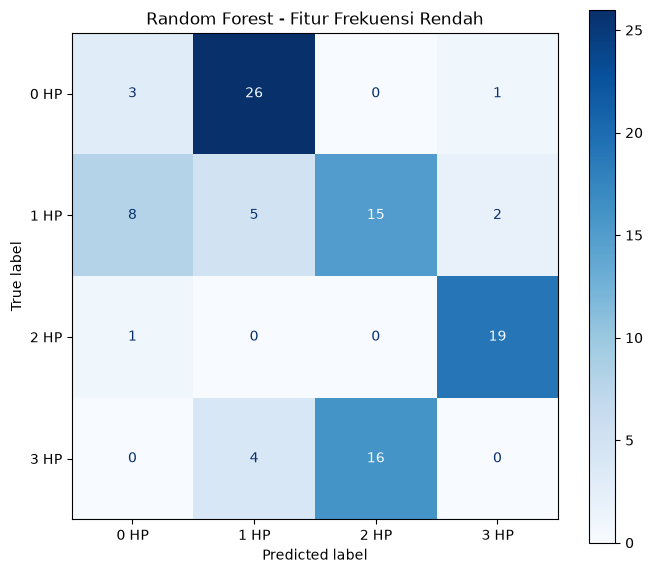

In [23]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

y_pred_new = model_rf_new.predict(X_test_new)

accuracy_new = accuracy_score(y_test_new, y_pred_new)
precision_new = precision_score(
    y_test_new, y_pred_new,
    average="macro", zero_division=0
)
recall_new = recall_score(
    y_test_new, y_pred_new,
    average="macro", zero_division=0
)
f1_new = f1_score(
    y_test_new, y_pred_new,
    average="macro", zero_division=0
)

print("HASIL RANDOM FOREST - FITUR BARU")
print("=" * 40)
print(f"Accuracy  : {accuracy_new:.4f}")
print(f"Precision : {precision_new:.4f}")
print(f"Recall    : {recall_new:.4f}")
print(f"F1-Score  : {f1_new:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_new,
        y_pred_new,
        labels=[0, 1, 2, 3],
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test_new,
    y_pred_new,
    labels=[0, 1, 2, 3],
    display_labels=["0 HP", "1 HP", "2 HP", "3 HP"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Random Forest - Fitur Frekuensi Rendah")
plt.tight_layout()
plt.show()


In [24]:

recording_eval = pd.DataFrame({
    "source_file": groups_new.loc[test_mask_new].to_numpy(),
    "actual": y_test_new.to_numpy(),
    "predicted": y_pred_new
})

recording_summary = (
    recording_eval.groupby("source_file")
    .agg(
        actual=("actual", "first"),
        predicted=("predicted", lambda x: x.mode().iloc[0]),
        segments=("predicted", "count")
    )
    .reset_index()
)

recording_summary["correct"] = (
    recording_summary["actual"]
    == recording_summary["predicted"]
)

display(recording_summary)

print(
    "Recording-level Accuracy:",
    round(recording_summary["correct"].mean(), 4)
)


,source_file,actual,predicted,segments,correct
0,108.mat,3,2,10,False
1,119.mat,1,0,10,False
2,130.mat,0,1,10,False
3,170.mat,1,1,10,True
4,185.mat,0,1,10,False
5,200.mat,3,2,10,False
6,211.mat,2,3,10,False
7,223.mat,1,2,10,False
8,234.mat,0,1,10,False
9,99.mat,2,3,10,False


Recording-level Accuracy: 0.1


In [25]:

# CELL 19 - ANALISIS KESALAHAN PER REKAMAN

recording_analysis = recording_summary.merge(
    df[
        ["source_file", "condition", "defect_size_inch"]
    ].drop_duplicates(),
    on="source_file",
    how="left"
)

display(
    recording_analysis[
        [
            "source_file",
            "condition",
            "defect_size_inch",
            "actual",
            "predicted",
            "correct"
        ]
    ].sort_values("source_file")
)

print("\nREKAMAN DENGAN PREDIKSI SALAH:")
display(
    recording_analysis.loc[
        ~recording_analysis["correct"]
    ]
)

print(
    "\nRecording-level Accuracy:",
    recording_analysis["correct"].mean()
)


,source_file,condition,defect_size_inch,actual,predicted,correct
0,108.mat,Inner Race,0.007,3,2,False
1,119.mat,Ball Fault,0.007,1,0,False
2,130.mat,Outer Race,0.007,0,1,False
3,170.mat,Inner Race,0.014,1,1,True
4,185.mat,Ball Fault,0.014,0,1,False
5,200.mat,Outer Race,0.014,3,2,False
6,211.mat,Inner Race,0.021,2,3,False
7,223.mat,Ball Fault,0.021,1,2,False
8,234.mat,Outer Race,0.021,0,1,False
9,99.mat,Normal,NaN,2,3,False



REKAMAN DENGAN PREDIKSI SALAH:


,source_file,actual,predicted,segments,correct,condition,defect_size_inch
0,108.mat,3,2,10,False,Inner Race,0.007
1,119.mat,1,0,10,False,Ball Fault,0.007
2,130.mat,0,1,10,False,Outer Race,0.007
4,185.mat,0,1,10,False,Ball Fault,0.014
5,200.mat,3,2,10,False,Outer Race,0.014
6,211.mat,2,3,10,False,Inner Race,0.021
7,223.mat,1,2,10,False,Ball Fault,0.021
8,234.mat,0,1,10,False,Outer Race,0.021
9,99.mat,2,3,10,False,Normal,NaN



Recording-level Accuracy: 0.1


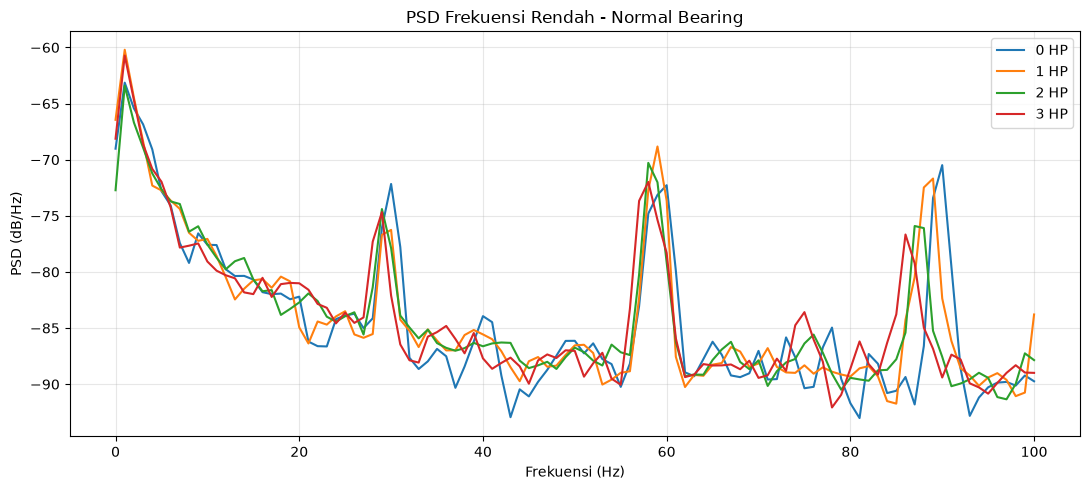

In [26]:

from scipy.signal import welch
import matplotlib.pyplot as plt
import numpy as np

normal_files = {
    0: "97.mat",
    1: "98.mat",
    2: "99.mat",
    3: "100.mat"
}

fig, ax = plt.subplots(figsize=(11, 5))

for load, file_name in normal_files.items():
    subset = signal_df[
        signal_df["source_file"] == file_name
    ].sort_values("sample_index")

    signal = subset["vibration"].to_numpy()

    # Hilangkan DC
    signal = signal - np.mean(signal)

    frequencies, psd = welch(
        signal,
        fs=12000,
        nperseg=12000
    )

    mask = (frequencies >= 0) & (frequencies <= 100)

    ax.plot(
        frequencies[mask],
        10 * np.log10(psd[mask] + 1e-20),
        label=f"{load} HP"
    )

ax.set_title("PSD Frekuensi Rendah - Normal Bearing")
ax.set_xlabel("Frekuensi (Hz)")
ax.set_ylabel("PSD (dB/Hz)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [27]:

# CELL 21 - EKSTRAKSI FITUR HARMONIK

from scipy.signal import welch
import numpy as np
import pandas as pd

FS = 12000
WINDOW_SIZE = 12000

harmonic_features = []

frequency_bands = {
    "fundamental": (25, 35),
    "harmonic_2": (50, 65),
    "harmonic_3": (80, 95)
}

for file_name, group in signal_df.groupby("source_file"):

    group = group.sort_values("sample_index")
    signal = group["vibration"].to_numpy()
    load = int(group["motor_load_hp"].iloc[0])

    n_segments = len(signal) // WINDOW_SIZE

    for i in range(n_segments):

        segment = signal[
            i * WINDOW_SIZE:(i + 1) * WINDOW_SIZE
        ]

        segment = segment - np.mean(segment)

        frequencies, psd = welch(
            segment,
            fs=FS,
            nperseg=WINDOW_SIZE
        )

        row = {
            "source_file": file_name,
            "segment_id": i,
            "motor_load_hp": load
        }

        for name, (low, high) in frequency_bands.items():

            mask = (
                (frequencies >= low) &
                (frequencies <= high)
            )

            band_freq = frequencies[mask]
            band_psd = psd[mask]

            peak_idx = np.argmax(band_psd)

            row[f"{name}_frequency"] = (
                band_freq[peak_idx]
            )

            row[f"{name}_power"] = (
                band_psd[peak_idx]
            )

        harmonic_features.append(row)

df_harmonic = pd.DataFrame(harmonic_features)

display(df_harmonic.head())

print("Jumlah segmen:", len(df_harmonic))
print("Jumlah rekaman:", df_harmonic["source_file"].nunique())

df_harmonic.to_csv(
    "outputs/bearing_features_harmonic.csv",
    index=False
)

print("Fitur harmonik berhasil disimpan.")



,source_file,segment_id,motor_load_hp,fundamental_frequency,fundamental_power,harmonic_2_frequency,harmonic_2_power,harmonic_3_frequency,harmonic_3_power
0,100.mat,0,3,29.0,3.157897e-08,59.0,6.068852e-08,86.0,2.151879e-08
1,100.mat,1,3,29.0,2.450639e-08,58.0,9.452766e-08,86.0,2.292923e-08
2,100.mat,2,3,29.0,1.745868e-08,58.0,5.820575e-08,86.0,3.285069e-08
3,100.mat,3,3,29.0,2.078117e-08,57.0,3.692090e-08,86.0,2.088012e-08
4,100.mat,4,3,29.0,3.649741e-08,58.0,5.403047e-08,86.0,3.318503e-08


Jumlah segmen: 395
Jumlah rekaman: 40
Fitur harmonik berhasil disimpan.


STATISTIK FREKUENSI HARMONIK


fundamental_frequency         harmonic_2_frequency          \
                               mean     std                 mean     std   
motor_load_hp                                                              
0                             30.00  0.0000                59.77  0.3498   
1                             29.89  0.0994                59.06  0.2011   
2                             29.00  0.0000                58.70  0.6055   
3                             28.95  0.1269                58.27  1.0012   

              harmonic_3_frequency          
                              mean     std  
motor_load_hp                               
0                            90.07  0.1636  
1                            88.96  0.0699  
2                            87.44  0.3864  
3                            85.97  0.3199

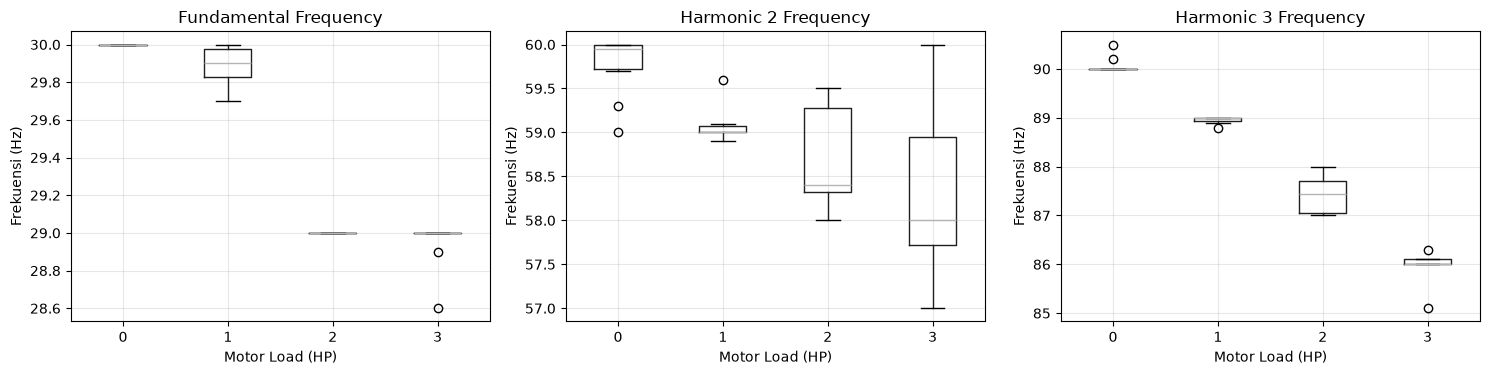

In [28]:

# CELL 22 - ANALISIS FITUR HARMONIK

import pandas as pd
import matplotlib.pyplot as plt

harmonic_columns = [
    "fundamental_frequency",
    "harmonic_2_frequency",
    "harmonic_3_frequency"
]

# Rata-rata fitur per rekaman
recording_harmonic = (
    df_harmonic
    .groupby(
        ["source_file", "motor_load_hp"],
        as_index=False
    )[harmonic_columns]
    .mean()
)

# Statistik berdasarkan beban motor
harmonic_summary = (
    recording_harmonic
    .groupby("motor_load_hp")[harmonic_columns]
    .agg(["mean", "std"])
)

print("STATISTIK FREKUENSI HARMONIK")
display(harmonic_summary.round(4))

# Visualisasi
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, harmonic_columns):

    recording_harmonic.boxplot(
        column=feature,
        by="motor_load_hp",
        ax=ax
    )

    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Motor Load (HP)")
    ax.set_ylabel("Frekuensi (Hz)")
    ax.grid(alpha=0.3)

plt.suptitle("")
plt.tight_layout()
plt.show()


In [29]:

# CELL 23 - DATASET FITUR HARMONIK

harmonic_feature_columns = [
    "fundamental_frequency",
    "fundamental_power",
    "harmonic_2_frequency",
    "harmonic_2_power",
    "harmonic_3_frequency",
    "harmonic_3_power"
]

X_harmonic = df_harmonic[harmonic_feature_columns]
y_harmonic = df_harmonic["motor_load_hp"].astype(int)
groups_harmonic = df_harmonic["source_file"]

train_mask_harmonic = groups_harmonic.isin(train_files)
test_mask_harmonic = groups_harmonic.isin(test_files)

X_train_harmonic = X_harmonic.loc[train_mask_harmonic]
X_test_harmonic = X_harmonic.loc[test_mask_harmonic]

y_train_harmonic = y_harmonic.loc[train_mask_harmonic]
y_test_harmonic = y_harmonic.loc[test_mask_harmonic]

assert set(
    groups_harmonic.loc[train_mask_harmonic]
).isdisjoint(
    set(groups_harmonic.loc[test_mask_harmonic])
)

print("Training segments:", len(X_train_harmonic))
print("Testing segments :", len(X_test_harmonic))

print("Training recordings:",
      groups_harmonic.loc[train_mask_harmonic].nunique())

print("Testing recordings:",
      groups_harmonic.loc[test_mask_harmonic].nunique())


Training segments: 285
Testing segments : 100
Training recordings: 29
Testing recordings: 10


In [30]:

from sklearn.ensemble import RandomForestClassifier

model_rf_harmonic = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_rf_harmonic.fit(
    X_train_harmonic,
    y_train_harmonic
)

print("Random Forest fitur harmonik berhasil dilatih!")


Random Forest fitur harmonik berhasil dilatih!


EVALUASI RANDOM FOREST - FITUR HARMONIK
Accuracy : 0.99
Macro F1 : 0.9875

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        30
           2       0.95      1.00      0.98        20
           3       1.00      0.95      0.97        20

    accuracy                           0.99       100
   macro avg       0.99      0.99      0.99       100
weighted avg       0.99      0.99      0.99       100



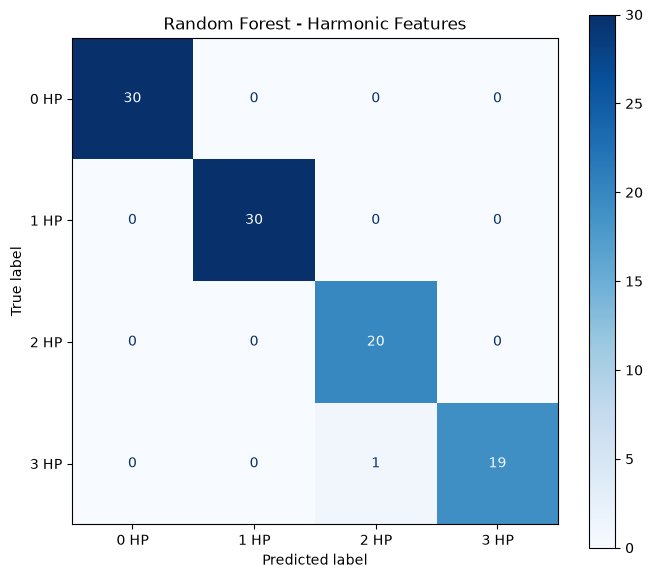

In [31]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

y_pred_harmonic = model_rf_harmonic.predict(
    X_test_harmonic
)

print("EVALUASI RANDOM FOREST - FITUR HARMONIK")
print("=" * 45)

print(
    "Accuracy :",
    round(
        accuracy_score(
            y_test_harmonic, y_pred_harmonic
        ), 4
    )
)

print(
    "Macro F1 :",
    round(
        f1_score(
            y_test_harmonic,
            y_pred_harmonic,
            average="macro",
            zero_division=0
        ), 4
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test_harmonic,
        y_pred_harmonic,
        labels=[0, 1, 2, 3],
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test_harmonic,
    y_pred_harmonic,
    labels=[0, 1, 2, 3],
    display_labels=["0 HP", "1 HP", "2 HP", "3 HP"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Random Forest - Harmonic Features")
plt.tight_layout()
plt.show()


In [32]:

recording_pred_harmonic = pd.DataFrame({
    "source_file": groups_harmonic.loc[
        test_mask_harmonic
    ].to_numpy(),
    "actual": y_test_harmonic.to_numpy(),
    "predicted": y_pred_harmonic
})

recording_result_harmonic = (
    recording_pred_harmonic
    .groupby("source_file")
    .agg(
        actual=("actual", "first"),
        predicted=("predicted", lambda x: x.mode().iloc[0]),
        segments=("predicted", "count")
    )
    .reset_index()
)

recording_result_harmonic["correct"] = (
    recording_result_harmonic["actual"]
    == recording_result_harmonic["predicted"]
)

display(recording_result_harmonic)

print(
    "Recording-level Accuracy:",
    recording_result_harmonic["correct"].mean()
)


,source_file,actual,predicted,segments,correct
0,108.mat,3,3,10,True
1,119.mat,1,1,10,True
2,130.mat,0,0,10,True
3,170.mat,1,1,10,True
4,185.mat,0,0,10,True
5,200.mat,3,3,10,True
6,211.mat,2,2,10,True
7,223.mat,1,1,10,True
8,234.mat,0,0,10,True
9,99.mat,2,2,10,True


Recording-level Accuracy: 1.0
